# FEMNIST computational cost analysis
This notebook analyzes **runtime only**: method comparisons, 100% versus 50% client participation, and pFLEDL calibration-epoch and warm-up ablations. Run all cells from a fresh kernel. Tables and publication figures are exported to `computation_cost_analysis` under the FEMNIST results directory.

## Experimental mapping and interpretation
- Original full-participation pFLEDL folders: warm-up **50**, calibration epochs 0/1/3/5. `pFLEDL_3_Second_Calib` is the archived three-epoch folder; `pFLEDL` is five epochs.
- `Partial Clients`: **50% participation, warm-up 50** for pFLEDL, one calibration epoch according to the filename. This corrects the earlier provisional warm-up interpretation. No partial 0/3/5-epoch pFLEDL runs are present.
- `EDL_30_Calib_Full`: **100% participation, warm-up 30**; calibration settings come from `EDL_0_Calib`, `EDL_1_Calib`, `EDL_3_Calib`, `EDL_5_Calib`. Their filenames all contain `calib5`, so directory labels take precedence. The manifest records both the assigned setting and its source. Mapping follows the researcher's supplied experiment history, not automatic verification of historical settings.

Runtime includes the work inside the recorded round timer: model updates/transfers, calibration, evaluation, local training, and aggregation. Clients execute sequentially. Simulated transfers do not measure deployed network latency. These data cannot separate calibration time from other round components. Hardware, evaluation schedule, and historical client-selection behavior must match before attributing differences solely to a configuration change.


In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results')
OUT = ROOT / 'computation_cost_analysis'
OUT.mkdir(exist_ok=True)
METHODS = ['FedAvg', 'FedALA', 'FedAS', 'FedROD', 'FedFomo', 'Ditto', 'APPLE', 'PerAvg']
SPECS = []
for method in METHODS:
    SPECS.append((method, 100, None, None, ROOT / method, 'baseline directory'))
    candidates = sorted((ROOT / 'Partial Clients').rglob(f'*_{method}_partial50*_timing.csv'))
    if not candidates:
        raise ValueError(f'Missing partial files: {method}')
    folders = {p.parent for p in candidates}
    if len(folders) != 1:
        raise ValueError(f'Ambiguous partial directories: {method}: {folders}')
    SPECS.append((method, 50, None, None, folders.pop(), 'partial archive'))
for epochs, folder in [(0, 'pFLEDL_0_Calib'), (1, 'pFLEDL_1_Calib'),
                       (3, 'pFLEDL_3_Second_Calib'), (5, 'pFLEDL')]:
    SPECS.append(('pFLEDL', 100, 50, epochs, ROOT / folder, 'researcher mapping: warm50 original archive'))
for epochs in [0, 1, 3, 5]:
    SPECS.append(('pFLEDL', 100, 30, epochs,
                  ROOT / 'EDL_30_Calib_Full' / f'EDL_{epochs}_Calib',
                  'researcher mapping; calibration from directory, overriding filename calib5'))
SPECS.append(('pFLEDL', 50, 50, 1, ROOT / 'Partial Clients' / 'pFLEDL_50_Percent_Clients',
              'researcher warm50 mapping; calib1 from filename'))

records, curves = [], {}
for method, participation, warmup, epochs, directory, provenance in SPECS:
    files = sorted(directory.glob('*_timing.csv'))
    if not files:
        raise ValueError(f'No timing files in {directory}')
    condition = (f'{method} | P{participation}' if method != 'pFLEDL' else
                 f'pFLEDL | P{participation} W{warmup} C{epochs}')
    seen_runs = set()
    for path in files:
        run_match = re.search(r'_(\d+)_timing\.csv$', path.name)
        if not run_match:
            raise ValueError(f'Unknown run identifier: {path}')
        run_id = int(run_match.group(1))
        if run_id in seen_runs:
            raise ValueError(f'Duplicate run id in {condition}: {run_id}')
        seen_runs.add(run_id)
        df = pd.read_csv(path).sort_values('round').reset_index(drop=True)
        required = ['round', 'round_time_sec', 'cumulative_time_sec']
        if df.empty or df[required].isna().any().any() or not np.isfinite(df[required].to_numpy()).all():
            raise ValueError(f'Invalid/missing timing data: {path}')
        if not np.array_equal(df['round'].to_numpy(), np.arange(len(df))) or (df.round_time_sec < 0).any():
            raise ValueError(f'Invalid rounds/durations: {path}')
        if not np.allclose(df.cumulative_time_sec, df.round_time_sec.cumsum()):
            raise ValueError(f'Cumulative timing mismatch: {path}')
        # Current implementation starts calibration when round_index + 1 >= warmup.
        onset = warmup - 1 if warmup is not None else None
        pre = df.loc[df['round'] < onset, 'round_time_sec'] if onset is not None else pd.Series(dtype=float)
        post = df.loc[df['round'] >= onset, 'round_time_sec'] if onset is not None else pd.Series(dtype=float)
        records.append(dict(condition=condition, method=method, participation=participation,
            warmup=warmup, calib_epochs=epochs, run=run_id, file=str(path), provenance=provenance,
            rounds=len(df), seconds_per_round=df.round_time_sec.mean(),
            total_minutes=df.cumulative_time_sec.iloc[-1]/60,
            pre_seconds=pre.mean(), post_seconds=post.mean(),
            post_rounds=len(post), post_fraction=len(post)/len(df) if onset is not None else np.nan))
        curves[(condition, run_id)] = df
runs = pd.DataFrame(records)
COMMON_N = int(runs['rounds'].min())
runs['common_minutes'] = [curves[(r.condition, r.run)].round_time_sec.iloc[:COMMON_N].sum()/60
                         for r in runs.itertuples()]
# An identical window entirely after both warm-up thresholds.
POST_START, POST_END = 49, COMMON_N
runs['shared_post_seconds'] = [curves[(r.condition, r.run)].round_time_sec.iloc[POST_START:POST_END].mean()
                              for r in runs.itertuples()]
print(f'Loaded {len(runs)} runs in {runs.condition.nunique()} conditions.')
print(f'Common budget: {COMMON_N} iterations including round 0; shared post-warm-up window: {POST_START}–{POST_END-1}.')
display(runs[['condition','run','rounds','file','provenance']])
runs.to_csv(OUT / 'run_manifest_and_metrics.csv', index=False)


Loaded 74 runs in 25 conditions.
Common budget: 57 iterations including round 0; shared post-warm-up window: 49–56.


,condition,run,rounds,file,provenance
0,FedAvg | P100,0,144,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/FedAvg/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedAvg_test_0_timing.csv,baseline directory
1,FedAvg | P100,1,142,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/FedAvg/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedAvg_test_1_timing.csv,baseline directory
2,FedAvg | P100,2,139,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/FedAvg/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedAvg_test_2_timing.csv,baseline directory
3,FedAvg | P50,0,72,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/Partial Clients/FedAvg_50_Percent_Client/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedAvg_partial50_calib1_0_timing.csv,partial archive
4,FedAvg | P50,1,89,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/Partial Clients/FedAvg_50_Percent_Client/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedAvg_partial50_calib1_1_timing.csv,partial archive
5,FedAvg | P50,2,84,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/Partial Clients/FedAvg_50_Percent_Client/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedAvg_partial50_calib1_2_timing.csv,partial archive
6,FedALA | P100,0,95,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/FedALA/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedALA_test_0_timing.csv,baseline directory
7,FedALA | P100,1,136,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/FedALA/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedALA_test_1_timing.csv,baseline directory
8,FedALA | P100,2,96,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/FedALA/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedALA_test_2_timing.csv,baseline directory
9,FedALA | P50,0,111,/home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/Partial Clients/FedALA_50_Percent_Client/FEMNIST-partition_pat-clients_20-cpc_4-balance_False-full-train_075_FedALA_partial50_calib1_0_timing.csv,partial archive


## Measurement definitions
For run $k$, let $N_k$ be the number of recorded iterations (including iteration 0) and $T_{k,r}=t^{end}_{k,r}-t^{start}_{k,r}$ its round duration. The notebook computes
\[
A_k=\frac{1}{N_k}\sum_{r=0}^{N_k-1}T_{k,r},\qquad
C_k=\frac{1}{60}\sum_{r=0}^{N_k-1}T_{k,r},\qquad
C_k^{(H)}=\frac{1}{60}\sum_{r=0}^{H-1}T_{k,r}.
\]
$H=\min_k N_k$ gives an identical number of iterations for every condition. $C_k$ is **cumulative recorded runtime**, not end-to-end process runtime: initialization and final saving outside round boundaries are excluded. Early stopping makes $C_k$ dependent on the run length.

Each table reports the mean and **sample** standard deviation across run-level measurements, giving equal weight to each run:
\[
\bar X=K^{-1}\sum_k X_k,\qquad
s_X=\sqrt{\frac{\sum_k(X_k-\bar X)^2}{K-1}}.
\]
For warm-up $W$, the assumed calibration onset is $r=W-1$, following the current `round_index + 1 >= warm_up` condition. Warm-up and post-warm-up means use $r<W-1$ and $r\ge W-1$. The shared post-warm-up window uses $49\le r<H$ for all conditions. It avoids comparing different round ranges, but can be short and is not a direct calibration timer.

An approximate work model for sequential execution is
\[
T_r \approx T_{\mathrm{other},r}+\sum_{i\in S_r}
\left(E_{\mathrm{train}}B_i^{\mathrm{train}}c_i^{\mathrm{train}}
+\mathbb{I}[r\ge W-1]E_{\mathrm{cal}}B_i^{\mathrm{cal}}c_i^{\mathrm{cal}}\right).
\]
Here $S_r$ denotes participating clients; $B_i$ counts minibatches per epoch and $c_i$ is runtime per minibatch update. This motivates approximately increasing runtime with calibration epochs; it is not a FLOP estimate or a fitted decomposition. Evaluation and other work need not halve with 50% participation. Warm-up-30 runs schedule 20 additional calibration-active iterations by a fixed horizon of at least 50 iterations, relative to warm-up 50.


In [2]:
METRICS = ['seconds_per_round', 'total_minutes', 'common_minutes', 'pre_seconds',
           'post_seconds', 'shared_post_seconds', 'post_fraction']
summary = runs.groupby('condition', sort=False).agg(
    method=('method','first'), participation=('participation','first'),
    warmup=('warmup','first'), calib_epochs=('calib_epochs','first'),
    K=('run','count'), min_rounds=('rounds','min'), max_rounds=('rounds','max'))
for metric in METRICS:
    grouped = runs.groupby('condition')[metric]
    summary[metric+'_mean'] = grouped.mean()
    summary[metric+'_sd'] = grouped.std()
summary.to_csv(OUT / 'condition_summary.csv')

def report_table(name, frame, metrics):
    table = frame[['K','min_rounds','max_rounds']].copy()
    for metric in metrics:
        table[metric] = [f'{a:.2f} ± {b:.2f}' if np.isfinite(a) else 'N/A'
                         for a,b in zip(frame[metric+'_mean'],frame[metric+'_sd'])]
    print(name)
    display(table)
    table.to_csv(OUT / (name+'.csv'))
    (OUT / (name+'.tex')).write_text(table.to_latex(escape=True), encoding='utf-8')
    return table

# Use the same pFLEDL calibration and warm-up settings in participation comparisons.
matched = summary[(summary.method != 'pFLEDL') |
                  ((summary.warmup == 50) & (summary.calib_epochs == 1))]
baseline_table = report_table('table1_methods_and_participation', matched,
                              ['seconds_per_round','total_minutes','common_minutes'])
pfl = summary[summary.method == 'pFLEDL']
ablation_table = report_table('table2_pfledl_ablation', pfl,
                              ['seconds_per_round','total_minutes','common_minutes'])
phase_table = report_table('table3_pfledl_phases', pfl,
                           ['pre_seconds','post_seconds','shared_post_seconds','post_fraction'])

# Ratios are descriptive ratios of group means, not paired-run estimates.
effects = []
for method in METHODS + ['pFLEDL']:
    subset = matched[matched.method == method].set_index('participation')
    full, partial = subset.loc[100], subset.loc[50]
    effects.append(dict(method=method, full_s=full.seconds_per_round_mean,
        partial_s=partial.seconds_per_round_mean,
        reduction_percent=100*(1-partial.seconds_per_round_mean/full.seconds_per_round_mean),
        full_over_partial=full.seconds_per_round_mean/partial.seconds_per_round_mean))
participation_effects = pd.DataFrame(effects).set_index('method')
display(participation_effects.round(2))
participation_effects.to_csv(OUT / 'table4_participation_effects.csv')
(OUT / 'table4_participation_effects.tex').write_text(participation_effects.to_latex(float_format='%.2f'))

warm_effects=[]
for epochs in [0,1,3,5]:
    a=pfl[(pfl.participation==100)&(pfl.calib_epochs==epochs)].set_index('warmup')
    warm_effects.append(dict(calib_epochs=epochs,
        W30_round_s=a.loc[30,'seconds_per_round_mean'], W50_round_s=a.loc[50,'seconds_per_round_mean'],
        W30_vs_W50_round_percent=100*(a.loc[30,'seconds_per_round_mean']/a.loc[50,'seconds_per_round_mean']-1),
        W30_common_min=a.loc[30,'common_minutes_mean'], W50_common_min=a.loc[50,'common_minutes_mean'],
        W30_vs_W50_common_percent=100*(a.loc[30,'common_minutes_mean']/a.loc[50,'common_minutes_mean']-1)))
warmup_effects=pd.DataFrame(warm_effects).set_index('calib_epochs')
display(warmup_effects.round(2))
warmup_effects.to_csv(OUT/'table5_warmup_effects.csv')
(OUT/'table5_warmup_effects.tex').write_text(warmup_effects.to_latex(float_format='%.2f'))

calibration_effects=[]
for w in [30,50]:
    sub=pfl[(pfl.participation==100)&(pfl.warmup==w)].set_index('calib_epochs')
    for e in [0,1,3,5]:
        calibration_effects.append(dict(warmup=w, calib_epochs=e,
            round_ratio_to_zero=sub.loc[e,'seconds_per_round_mean']/sub.loc[0,'seconds_per_round_mean'],
            shared_post_ratio_to_zero=sub.loc[e,'shared_post_seconds_mean']/sub.loc[0,'shared_post_seconds_mean'],
            shared_post_extra_s=sub.loc[e,'shared_post_seconds_mean']-sub.loc[0,'shared_post_seconds_mean']))
calibration_effects=pd.DataFrame(calibration_effects)
display(calibration_effects.round(2))
calibration_effects.to_csv(OUT/'table6_calibration_overhead.csv',index=False)
(OUT/'table6_calibration_overhead.tex').write_text(calibration_effects.to_latex(index=False,float_format='%.2f'))


table1_methods_and_participation
table2_pfledl_ablation
table3_pfledl_phases


,K,min_rounds,max_rounds,seconds_per_round,total_minutes,common_minutes
condition,,,,,,
FedAvg | P100,3,139,144,70.09 ± 0.30,165.49 ± 2.43,66.00 ± 0.38
FedAvg | P50,3,72,89,49.82 ± 0.55,67.83 ± 7.48,46.97 ± 0.52
FedALA | P100,3,95,136,92.30 ± 0.62,167.84 ± 37.22,88.81 ± 0.45
FedALA | P50,3,103,112,72.40 ± 0.73,131.15 ± 6.66,69.79 ± 0.58
FedAS | P100,3,70,86,194.90 ± 0.59,261.01 ± 29.84,184.87 ± 0.16
FedAS | P50,3,75,95,136.65 ± 0.23,193.58 ± 22.62,129.12 ± 0.97
FedROD | P100,3,99,127,86.82 ± 0.22,169.27 ± 22.21,81.81 ± 0.62
FedROD | P50,3,104,119,59.03 ± 0.28,108.23 ± 8.17,55.40 ± 1.08
FedFomo | P100,3,57,75,75.26 ± 0.35,81.53 ± 11.53,71.45 ± 0.43


,K,min_rounds,max_rounds,seconds_per_round,total_minutes,common_minutes
condition,,,,,,
pFLEDL | P100 W50 C0,3,139,144,72.79 ± 0.28,171.86 ± 2.39,65.96 ± 0.72
pFLEDL | P100 W50 C1,3,124,128,119.33 ± 0.90,249.28 ± 6.23,76.55 ± 0.90
pFLEDL | P100 W50 C3,3,128,136,215.08 ± 2.03,472.07 ± 18.93,96.19 ± 1.34
pFLEDL | P100 W50 C5,3,124,132,309.37 ± 6.12,665.44 ± 35.30,117.20 ± 0.43
pFLEDL | P100 W30 C0,3,139,144,74.01 ± 0.31,174.74 ± 3.54,68.50 ± 0.69
pFLEDL | P100 W30 C1,3,116,122,130.29 ± 1.09,256.27 ± 9.70,103.26 ± 0.65
pFLEDL | P100 W30 C3,3,118,127,245.80 ± 1.92,498.51 ± 23.15,173.61 ± 1.01
pFLEDL | P100 W30 C5,3,117,132,362.07 ± 7.26,748.87 ± 60.55,243.98 ± 1.28
pFLEDL | P50 W50 C1,3,113,131,195.37 ± 4.90,403.19 ± 40.47,134.48 ± 1.39


,K,min_rounds,max_rounds,pre_seconds,post_seconds,shared_post_seconds,post_fraction
condition,,,,,,,
pFLEDL | P100 W50 C0,3,139,144,68.51 ± 0.96,75.07 ± 0.93,75.08 ± 0.86,0.65 ± 0.01
pFLEDL | P100 W50 C1,3,124,128,68.94 ± 1.23,151.68 ± 1.70,151.86 ± 1.24,0.61 ± 0.01
pFLEDL | P100 W50 C3,3,128,136,68.52 ± 1.58,302.07 ± 1.95,301.71 ± 1.62,0.63 ± 0.01
pFLEDL | P100 W50 C5,3,124,132,69.13 ± 0.48,456.67 ± 2.36,455.61 ± 3.78,0.62 ± 0.01
pFLEDL | P100 W30 C0,3,139,144,69.09 ± 1.81,75.28 ± 0.59,75.30 ± 0.37,0.80 ± 0.00
pFLEDL | P100 W30 C1,3,116,122,68.54 ± 1.73,150.41 ± 1.09,151.07 ± 1.15,0.75 ± 0.01
pFLEDL | P100 W30 C3,3,118,127,68.53 ± 2.49,301.34 ± 1.64,300.77 ± 1.83,0.76 ± 0.01
pFLEDL | P100 W30 C5,3,117,132,68.53 ± 1.10,451.94 ± 3.46,453.68 ± 5.42,0.77 ± 0.01
pFLEDL | P50 W50 C1,3,113,131,125.54 ± 0.78,241.38 ± 2.69,239.67 ± 5.89,0.60 ± 0.03


,full_s,partial_s,reduction_percent,full_over_partial
method,,,,
FedAvg,70.09,49.82,28.91,1.41
FedALA,92.30,72.40,21.56,1.27
FedAS,194.90,136.65,29.89,1.43
FedROD,86.82,59.03,32.02,1.47
FedFomo,75.26,52.30,30.50,1.44
Ditto,119.26,74.33,37.67,1.60
APPLE,446.71,447.41,-0.16,1.00
PerAvg,139.58,95.60,31.51,1.46
pFLEDL,119.33,195.37,-63.72,0.61


,W30_round_s,W50_round_s,W30_vs_W50_round_percent,W30_common_min,W50_common_min,W30_vs_W50_common_percent
calib_epochs,,,,,,
0,74.01,72.79,1.67,68.50,65.96,3.86
1,130.29,119.33,9.18,103.26,76.55,34.88
3,245.80,215.08,14.28,173.61,96.19,80.49
5,362.07,309.37,17.03,243.98,117.20,108.17


,warmup,calib_epochs,round_ratio_to_zero,shared_post_ratio_to_zero,shared_post_extra_s
0,30,0,1.00,1.00,0.00
1,30,1,1.76,2.01,75.77
2,30,3,3.32,3.99,225.47
3,30,5,4.89,6.02,378.38
4,50,0,1.00,1.00,0.00
5,50,1,1.64,2.02,76.78
6,50,3,2.95,4.02,226.63
7,50,5,4.25,6.07,380.53


Tables exported to /home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/computation_cost_analysis; publication PDFs exported to /home/khoa/Khoa/PFLLib/results/Wahab/FEMNIST Results/computation_cost_analysis/publication_figures


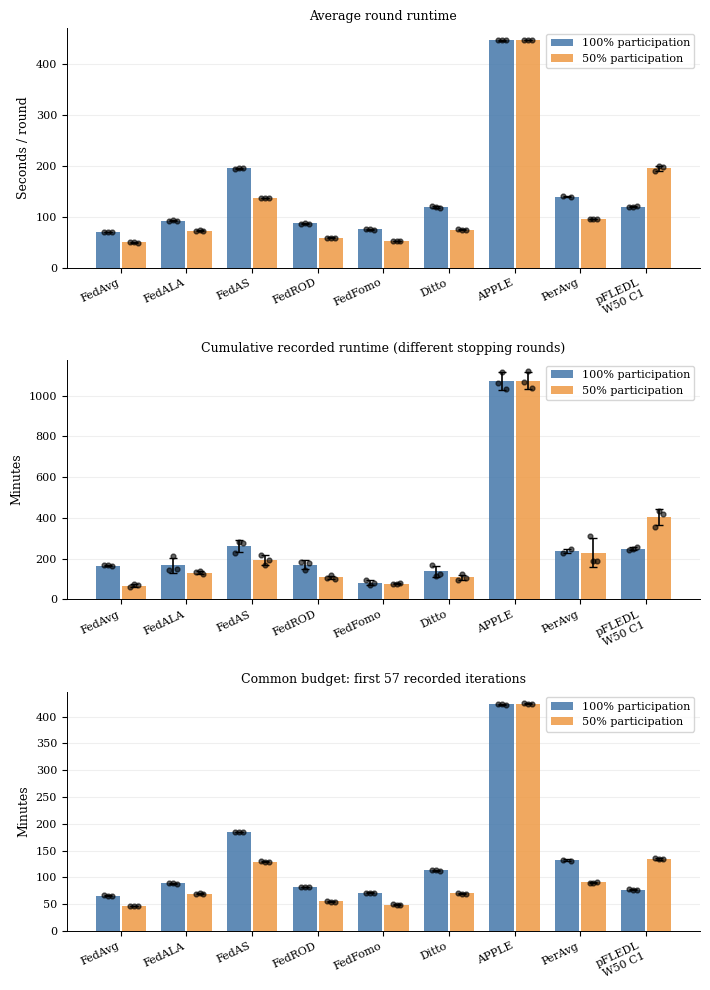

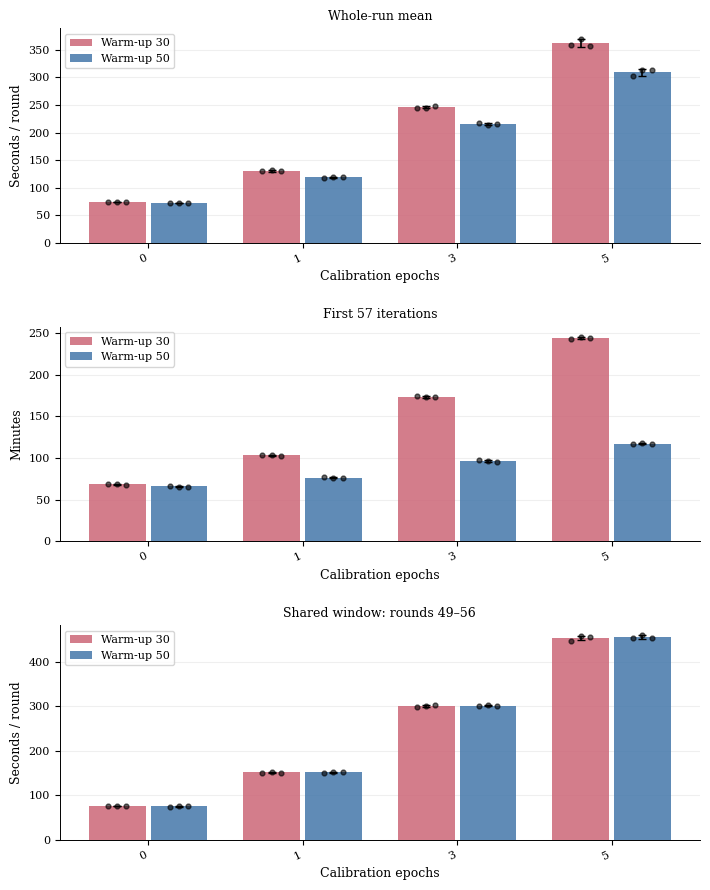

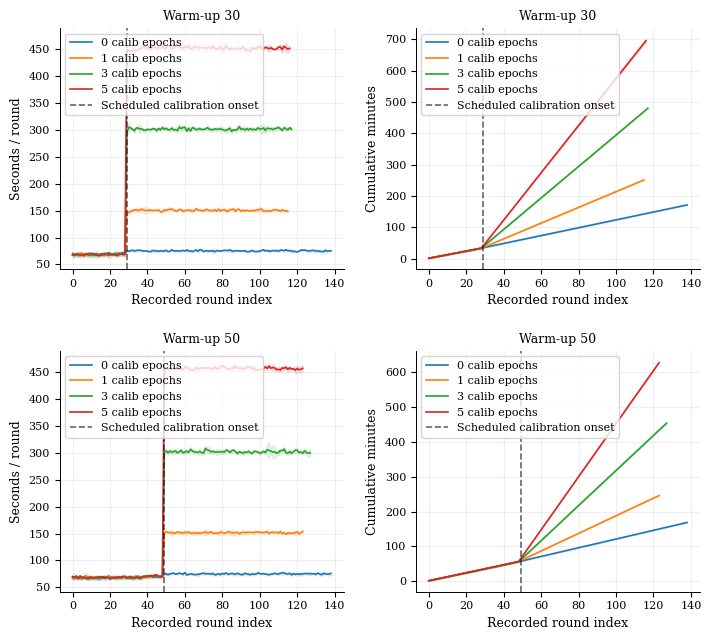

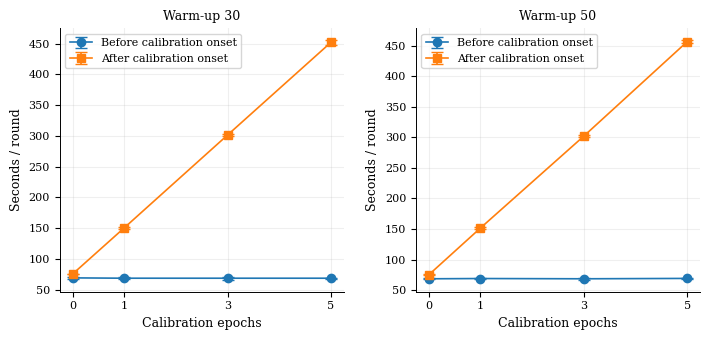

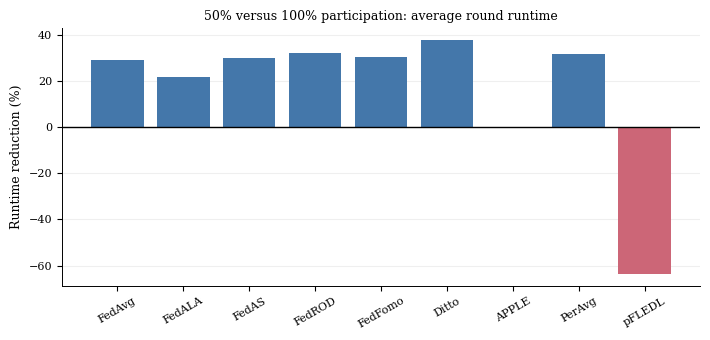

In [3]:
COLORS = {100:'#4477AA',50:'#EE9944',30:'#CC6677'}
plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
    'font.size': 9, 'axes.labelsize': 9, 'axes.titlesize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 0.7, 'lines.linewidth': 1.2,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'savefig.facecolor': 'white', 'figure.facecolor': 'white',
})
FIGURE_OUT = OUT / 'publication_figures'
FIGURE_OUT.mkdir(exist_ok=True)
def save_figure(fig, name):
    fig.tight_layout(pad=1.2, w_pad=1.8, h_pad=2.0)
    fig.savefig(FIGURE_OUT / f'{name}.pdf', format='pdf',
                bbox_inches='tight', pad_inches=0.06,
                metadata={'Title': name.replace('_', ' '),
                          'Subject': 'FEMNIST computational cost analysis'})
    plt.show()

def grouped_bars(ax, groups, labels, metric, title, ylabel):
    x=np.arange(len(labels)); width=0.8/len(groups)
    for j,(legend,conditions,color) in enumerate(groups):
        pos=x-0.4+width*(j+0.5)
        means=[summary.loc[c,metric+'_mean'] for c in conditions]
        sd=[summary.loc[c,metric+'_sd'] for c in conditions]
        ax.bar(pos,means,width=width*0.92,yerr=sd,capsize=3,label=legend,color=color,alpha=0.85)
        for xp,c in zip(pos,conditions):
            v=runs.loc[runs.condition==c,metric].to_numpy()
            ax.scatter(xp+np.linspace(-width*.15,width*.15,len(v)),v,s=12,color='black',zorder=3,alpha=.6)
    ax.set_xticks(x,labels,rotation=25,ha='right');ax.set(title=title,ylabel=ylabel)
    ax.set_ylim(bottom=0);ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True);ax.legend()

labels=METHODS+['pFLEDL\nW50 C1']
groups=[]
for part in [100,50]:
    conditions=[matched[(matched.method==m)&(matched.participation==part)].index[0] for m in METHODS+['pFLEDL']]
    groups.append((f'{part}% participation',conditions,COLORS[part]))
fig,axes=plt.subplots(3,1,figsize=(7.2,10))
for ax,metric,title,ylabel in zip(axes,['seconds_per_round','total_minutes','common_minutes'],
        ['Average round runtime','Cumulative recorded runtime (different stopping rounds)',f'Common budget: first {COMMON_N} recorded iterations'],
        ['Seconds / round','Minutes','Minutes']):
    grouped_bars(ax,groups,labels,metric,title,ylabel)
save_figure(fig,'femnist_runtime_full_vs_partial_participation')

fig,axes=plt.subplots(3,1,figsize=(7.2,9))
groups=[(f'Warm-up {w}',[f'pFLEDL | P100 W{w} C{e}' for e in [0,1,3,5]],COLORS[w if w==30 else 100]) for w in [30,50]]
for ax,metric,title,ylabel in zip(axes,['seconds_per_round','common_minutes','shared_post_seconds'],
    ['Whole-run mean',f'First {COMMON_N} iterations',f'Shared window: rounds {POST_START}–{POST_END-1}'],
    ['Seconds / round','Minutes','Seconds / round']):
    grouped_bars(ax,groups,['0','1','3','5'],metric,title,ylabel)
    ax.set_xlabel('Calibration epochs')
save_figure(fig,'pfledl_runtime_warmup_and_calibration_ablation')

fig,axes=plt.subplots(2,2,figsize=(7.2,6.5))
for row,w in enumerate([30,50]):
    for e in [0,1,3,5]:
        cond=f'pFLEDL | P100 W{w} C{e}'
        data=[df for (c,k),df in curves.items() if c==cond]
        n=min(map(len,data)); x=np.arange(n)
        for col,field,scale in [(0,'round_time_sec',1),(1,'cumulative_time_sec',60)]:
            values=np.array([df[field].iloc[:n].to_numpy()/scale for df in data])
            mean,sd=values.mean(axis=0),values.std(axis=0,ddof=1)
            line,=axes[row,col].plot(x,mean,label=f'{e} calib epochs')
            axes[row,col].fill_between(x,np.maximum(0,mean-sd),mean+sd,color=line.get_color(),alpha=.12)
    for col in [0,1]:
        axes[row,col].axvline(w-1,color='black',ls='--',alpha=.6,label='Scheduled calibration onset')
        axes[row,col].set(title=f'Warm-up {w}',xlabel='Recorded round index',
                         ylabel='Seconds / round' if col==0 else 'Cumulative minutes')
        axes[row,col].legend(fontsize=8);axes[row,col].grid(alpha=.2)
save_figure(fig,'pfledl_per_round_and_cumulative_runtime_profiles')

fig,axes=plt.subplots(1,2,figsize=(7.2,3.5))
for ax,w in zip(axes,[30,50]):
    for phase,label,marker in [('pre_seconds','Before calibration onset','o'),('post_seconds','After calibration onset','s')]:
        sub=pfl[(pfl.participation==100)&(pfl.warmup==w)].sort_values('calib_epochs')
        ax.errorbar(sub.calib_epochs,sub[phase+'_mean'],yerr=sub[phase+'_sd'],marker=marker,capsize=4,label=label)
    ax.set(title=f'Warm-up {w}',xlabel='Calibration epochs',ylabel='Seconds / round',xticks=[0,1,3,5]);ax.legend();ax.grid(alpha=.2)
save_figure(fig,'pfledl_runtime_before_and_after_calibration_onset')

fig,ax=plt.subplots(figsize=(7.2,3.5))
vals=participation_effects.reduction_percent
ax.bar(vals.index,vals,color=['#4477AA' if v>=0 else '#CC6677' for v in vals])
ax.axhline(0,color='black',lw=1);ax.tick_params(axis='x',rotation=30)
ax.set(ylabel='Runtime reduction (%)',title='50% versus 100% participation: average round runtime')
ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
save_figure(fig,'femnist_round_runtime_reduction_partial_participation')

print(f'Tables exported to {OUT}; publication PDFs exported to {FIGURE_OUT}')


pFLEDL-only matched horizon: 116 iterations; post-onset window: rounds 49–115.


,K,fixed_minutes_mean,fixed_minutes_sd,fixed_post_s_mean,fixed_post_s_sd
condition,,,,,
pFLEDL | P100 W50 C0,3,139.74,0.49,75.04,0.89
pFLEDL | P100 W50 C1,3,225.70,0.95,151.70,1.75
pFLEDL | P100 W50 C3,3,393.26,1.17,302.06,1.90
pFLEDL | P100 W50 C5,3,566.58,2.34,456.83,2.33
pFLEDL | P100 W30 C0,3,142.57,0.57,75.32,0.50
pFLEDL | P100 W30 C1,3,251.23,0.98,150.56,1.07
pFLEDL | P100 W30 C3,3,470.09,1.37,301.42,2.08
pFLEDL | P100 W30 C5,3,688.31,4.71,452.08,3.77


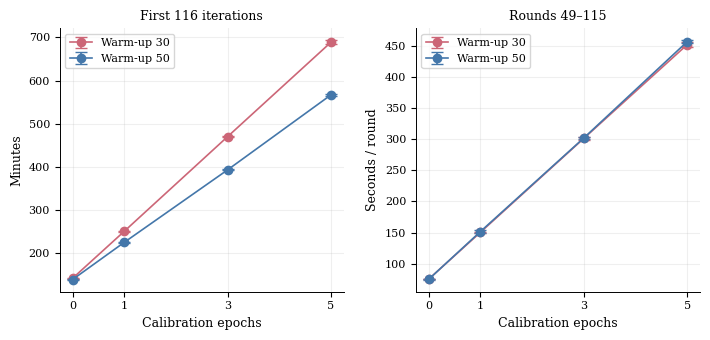

In [4]:
# Longer matched horizon for the full-participation pFLEDL ablation only.
full_pfl_runs = runs[(runs.method=='pFLEDL') & (runs.participation==100)].copy()
PFL_H = int(full_pfl_runs['rounds'].min())
full_pfl_runs['fixed_horizon_minutes'] = [curves[(r.condition,r.run)].round_time_sec.iloc[:PFL_H].sum()/60
                                         for r in full_pfl_runs.itertuples()]
full_pfl_runs['fixed_post_seconds'] = [curves[(r.condition,r.run)].round_time_sec.iloc[49:PFL_H].mean()
                                      for r in full_pfl_runs.itertuples()]
pfl_fixed = full_pfl_runs.groupby('condition',sort=False).agg(
    K=('run','count'),fixed_minutes_mean=('fixed_horizon_minutes','mean'),
    fixed_minutes_sd=('fixed_horizon_minutes','std'),
    fixed_post_s_mean=('fixed_post_seconds','mean'),fixed_post_s_sd=('fixed_post_seconds','std'))
print(f'pFLEDL-only matched horizon: {PFL_H} iterations; post-onset window: rounds 49–{PFL_H-1}.')
display(pfl_fixed.round(2))
pfl_fixed.to_csv(OUT/'table7_pfledl_longer_matched_horizon.csv')
(OUT/'table7_pfledl_longer_matched_horizon.tex').write_text(pfl_fixed.to_latex(float_format='%.2f'))
fig,axes=plt.subplots(1,2,figsize=(7.2,3.5))
for w,color in [(30,'#CC6677'),(50,'#4477AA')]:
    conditions=[f'pFLEDL | P100 W{w} C{e}' for e in [0,1,3,5]]
    sub=pfl_fixed.loc[conditions]
    for ax,metric,err,title,ylabel in [
        (axes[0],'fixed_minutes_mean','fixed_minutes_sd',f'First {PFL_H} iterations','Minutes'),
        (axes[1],'fixed_post_s_mean','fixed_post_s_sd',f'Rounds 49–{PFL_H-1}','Seconds / round')]:
        ax.errorbar([0,1,3,5],sub[metric],yerr=sub[err],marker='o',capsize=4,color=color,label=f'Warm-up {w}')
        ax.set(title=title,xlabel='Calibration epochs',ylabel=ylabel,xticks=[0,1,3,5]);ax.grid(alpha=.2);ax.legend()
save_figure(fig,'pfledl_runtime_ablation_fixed_iteration_budget')


## Reading the ablation and selecting manuscript evidence
1. **Method comparison:** Table 1 and Figure 1 compare observed costs at both participation ratios. Use pFLEDL W50 C1 for the matched participation comparison; do not combine it with a W30 or C5 result under a single pFLEDL label.
2. **Calibration ablation:** Table 2, Table 6, and Figure 2 isolate 0/1/3/5 scheduled calibration epochs within each full-participation warm-up setting. The common-round metric controls the number of iterations; the shared post-warm-up window compares rounds where both schedules have activated calibration.
3. **Warm-up ablation:** Table 5 compares W30 and W50 at the same epoch setting. Earlier onset increases the number of calibration-active rounds at a fixed horizon; whole-run totals also depend on stopping. C0 is a useful control: any W30/W50 difference at C0 is not caused by calibration optimizer steps and may reflect runtime conditions or implementation overhead.
4. **Timing profiles:** Figure 3 shows whether observed timing transitions align with assigned onset. Mismatches warrant checking historical code/configuration rather than relabeling runs to fit the timing. Bands use a fixed set of runs within each curve and stop at the shortest run for that condition.
5. **Phase analysis:** Table 3 and Figure 4 separate before/after-onset averages, but their differences include other time-varying work. They must not be described as separately measured calibration duration.

### Limits and missing experiments
There is no complete participation × warm-up × calibration factorial design: partial-participation W30 and partial C0/C3/C5 are absent. Consequently, warm-up and calibration ablations are supported only at full participation. Ratios and percentage changes are descriptive estimates from condition means, not significance tests. SD describes between-run spread, not a confidence interval or within-run timing variability. A runtime-only analysis quantifies cost but cannot establish whether the additional cost is justified by predictive benefits.

For the manuscript, use the method-comparison table, the pFLEDL ablation table, and one ablation figure as the main evidence. Remaining tables and timing profiles suit supplementary material. All figures are exported only as vector PDFs with embedded TrueType fonts in `publication_figures` and all tables as CSV and LaTeX.


## Findings for the manuscript
**Calibration introduces substantial and approximately epoch-proportional work.** After the scheduled onset, full-participation W30 round costs are 75.28, 150.41, 301.34, and 451.94 seconds for 0, 1, 3, and 5 calibration epochs. W50 gives 75.07, 151.68, 302.07, and 456.67 seconds. Thus, relative to C0, the observed active-phase costs are approximately 2×, 4×, and 6× for C1, C3, and C5. These ratios describe complete rounds, not isolated calibration kernels. Reducing calibration epochs directly reduces the measured simulation cost.

**Warm-up mainly changes how many expensive rounds are executed.** W30 versus W50 whole-run means are 130.29 versus 119.33 seconds (C1), 245.80 versus 215.08 (C3), and 362.07 versus 309.37 (C5): increases of 9.18%, 14.28%, and 17.03%. Active-phase costs are similar descriptively across warm-ups; earlier onset produces additional calibration-active iterations. Table 7 and Figure 6 control the iteration horizon specifically for the full pFLEDL ablation and use a longer post-onset window than the all-method comparison. Use them as primary ablation evidence rather than the short shared window in Figure 2.

**Total recorded cost is affected by termination.** Always report executed-round ranges with cumulative time. Equal-round comparisons control this factor but do not equalize total client updates across participation ratios. The C0 W30/W50 difference (74.01 versus 72.79 seconds per round) provides a measure of background variation; warm-up cannot add calibration optimizer updates when C=0.

**Partial participation does not uniformly reduce recorded cost.** Most baselines reduce average round time by approximately 22–38%, whereas APPLE is almost unchanged. Archived partial pFLEDL costs 195.37 versus 119.33 seconds per round for full participation at the supplied W50 C1 mapping. Importantly, its before-onset cost is already 125.54 versus 68.94 seconds. The slowdown therefore predates calibration and cannot be explained solely by the extra calibration epochs or by a W30/W50 mismatch under the corrected mapping. Check the historical evaluation/client-update scope and execution conditions before making a causal claim about participation. Keep these observed values visible; do not present them as evidence that partial participation necessarily accelerates pFLEDL.

**Suggested subsection order:** measurement protocol and equations; method comparison at both participation ratios; full-participation calibration/warm-up ablation; implementation scope and remaining configuration caveats. Tables 1, 2, and 7 plus Figures 1 and 6 are the strongest main-text candidates; phase profiles and additional ratio tables can go in the supplement.
